<a href="https://colab.research.google.com/github/isabeltran2029/CURSO-LENGUAJE-DE-PROGRAMACION/blob/main/S19_Analisis_Exploratorio_Portafolios.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 Actividad de Evaluación: Análisis Exploratorio de Portafolios (10%)

**Instrucciones:**
1. Resuelve cada uno de los puntos solicitados utilizando código de Python limpio y ordenado.
2. No olvides acompañar cada visualización con su respectiva **interpretación analítica** (recuerda la regla de oro: qué observas y qué significa).
3. Puedes realizar esta actividad de forma individual o en parejas (según las indicaciones del docente).

---

## 🏦 Paso 1: Selección y Descarga de Datos

1. Selecciona **3 activos financieros** diferentes a los utilizados en la clase (evita usar AAPL, MSFT, GOOGL, AMZN o NVDA).
2. Descarga los datos históricos utilizando `yfinance` para el periodo del **1 de enero de 2024** al **1 de enero de 2026**.
3. Muestra las primeras 5 filas del DataFrame resultante para validar la descarga.

In [1]:
# Escribe aquí tu código para descargar los datos de tus 3 activos elegidos
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Activos asignados
tickers = ["BLK", "GE", "ADBE"]

# Descargar datos
datos = yf.download(
    tickers,
    start="2024-01-01",
    end="2026-01-01"
)

# Mostrar primeras filas
datos.head()

/tmp/ipykernel_2160/504670060.py:12: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download(
[*********************100%***********************]  3 of 3 completed


Price            Close                                High              \
Ticker            ADBE         BLK          GE        ADBE         BLK   
Date                                                                     
2024-01-02  580.070007  753.558472   98.875839  590.440002  760.940602   
2024-01-03  571.789978  738.351807   97.392105  577.299988  746.129334   
2024-01-04  567.049988  740.046570   97.863136  572.909973  746.204580   
2024-01-05  564.599976  737.108765   99.142738  569.520020  742.692416   
2024-01-08  580.549988  750.630066  100.704971  581.510010  751.402181   

Price                          Low                               Open  \
Ticker              GE        ADBE         BLK         GE        ADBE   
Date                                                                    
2024-01-02  100.602933  576.760010  748.972909  98.318465  589.510010   
2024-01-03   98.302747  570.190002  736.638097  97.070236  574.580017   
2024-01-04   98.734529  566.659973  737.014604  97.478468  570.989990   
2024-01-05   99.181988  563.340027  735.818784  97.918070  563.500000   
2024-01-08  100.822735  567.869995  737.184063  97.509862  567.869995   

Price                               Volume                   
Ticker             BLK         GE     ADBE     BLK       GE  
Date                                                         
2024-01-02  757.183647  99.707983  2840200  660000  5189425  
2024-01-03  746.129334  98.224248  2478000  638700  4531850  
2024-01-04  737.513677  97.580517  2092100  580200  4364199  
2024-01-05  737.089914  98.051526  1923200  471000  4190157  
2024-01-08  738.615305  99.087792  2830000  513200  6920068

## 📈 Paso 2: Análisis de Precios de Cierre y Normalización

1. Filtra y extrae únicamente los precios de cierre (`Close`).
2. Grafica en una sola figura la evolución temporal de los precios originales de tus 3 activos.
3. Realiza la normalización (base 100 en el primer registro) y grafica nuevamente las series en otra figura.

### 💬 Pregunta de interpretación #1:
Al comparar ambos gráficos (precios reales vs. precios normalizados), ¿por qué es metodológicamente más correcto utilizar el gráfico normalizado para comparar el rendimiento histórico de los activos? Explica la diferencia en el comportamiento visual observado.

"respuesta Isabel Beltran"
El gráfico normalizado permite comparar el comportamiento de los activos en igualdad de condiciones porque todos comienzan en el mismo valor (100). En cambio, los precios originales pueden generar interpretaciones equivocadas debido a que cada acción tiene un precio de mercado diferente. Con la normalización es posible identificar con mayor facilidad cuál activo presentó una mayor rentabilidad relativa durante el período, independientemente de su precio inicial. Visualmente, el gráfico normalizado muestra de forma más clara las diferencias en crecimiento o disminución porcentual de cada activo.

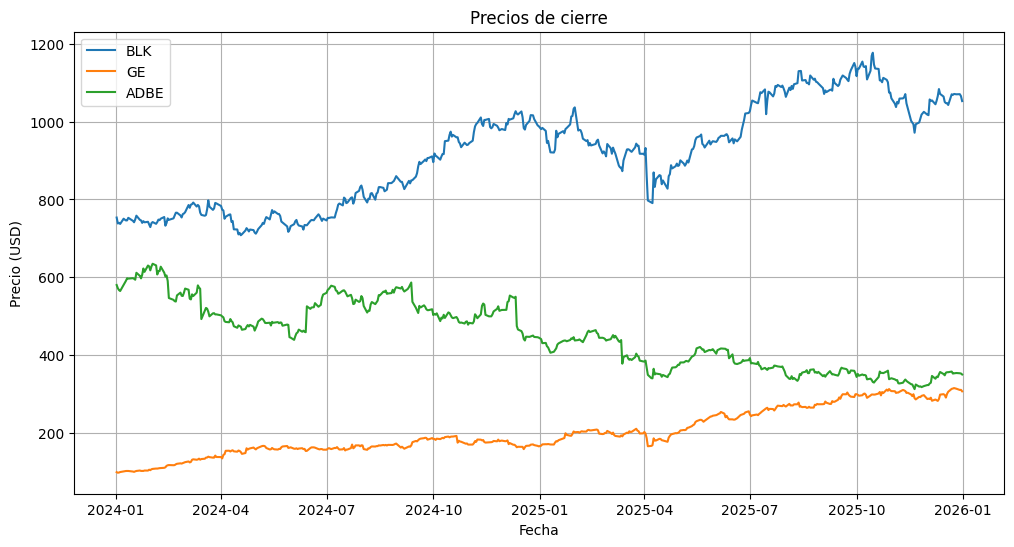

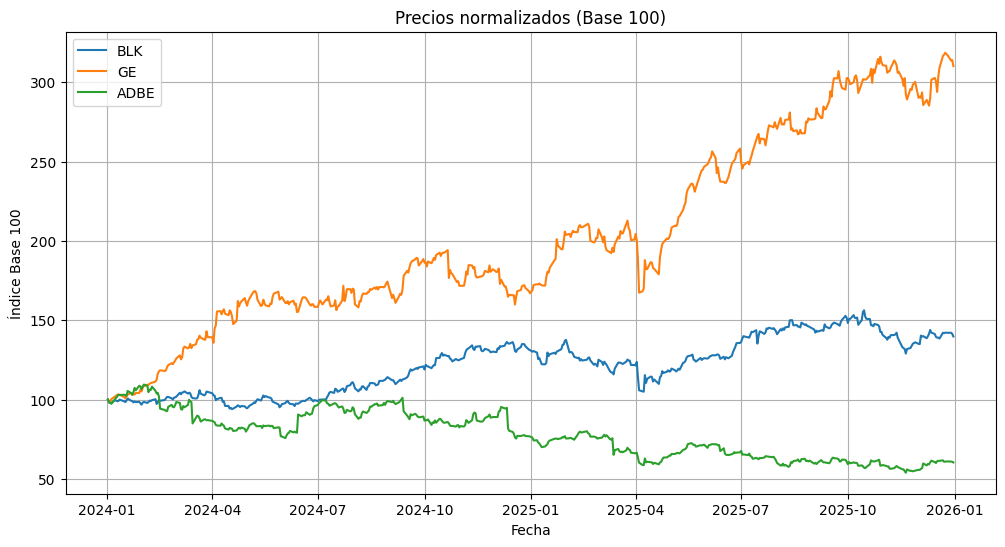

In [2]:
# 1. Extraer los precios de cierre
cierres = datos["Close"]

# 2. Graficar precios originales
plt.figure(figsize=(12,6))
for ticker in tickers:
    plt.plot(cierres.index, cierres[ticker], label=ticker)

plt.title("Precios de cierre")
plt.xlabel("Fecha")
plt.ylabel("Precio (USD)")
plt.legend()
plt.grid(True)
plt.show()

# 3. Normalizar y graficar en base 100
base100 = cierres / cierres.iloc[0] * 100

# Gráfico normalizado
plt.figure(figsize=(12,6))
for ticker in tickers:
    plt.plot(base100.index, base100[ticker], label=ticker)

plt.title("Precios normalizados (Base 100)")
plt.xlabel("Fecha")
plt.ylabel("Índice Base 100")
plt.legend()
plt.grid(True)
plt.show()


## 🔄 Paso 3: Cálculo y Distribución de Rendimientos

1. Calcula los rendimientos diarios de los activos y elimina los valores nulos (`NaN`).
2. Genera un **histograma* para el activo que consideres que haya sido el más volátil.
3. Diseña un **Boxplot** comparativo que muestre los rendimientos diarios de tus 3 activos simultáneamente.

### 💬 Pregunta de interpretación #2:
Observando el Boxplot y el Histograma:
- ¿Qué activo presenta la mayor dispersión (caja más amplia o bigotes más largos) y qué te dice esto sobre su riesgo?
- ¿Identificas valores atípicos (outliers)? ¿Qué representan estos puntos en el contexto de la historia económica reciente de estas empresas?

"RESPUESTA ISABEL BELTRAN"
El activo que presente la caja más amplia y los bigotes más largos en el boxplot será el que tenga mayor volatilidad. Una mayor dispersión indica que los rendimientos presentan fluctuaciones más fuertes, por lo que el riesgo de inversión también es más elevado. Los inversionistas suelen exigir una mayor rentabilidad esperada para compensar este riesgo adicional.

Sí es posible identificar valores atípicos u outliers. Estos representan movimientos extraordinarios en el precio de la acción ocasionados por eventos relevantes como publicaciones de resultados financieros, cambios en las expectativas económicas, anuncios corporativos, innovaciones tecnológicas o situaciones de incertidumbre en los mercados financieros. Los outliers reflejan momentos en los que el mercado reaccionó de forma inusual frente a información nueva.

Volatilidades:
Ticker
ADBE    0.021241
BLK     0.014659
GE      0.019161
dtype: float64
Activo más volátil: ADBE


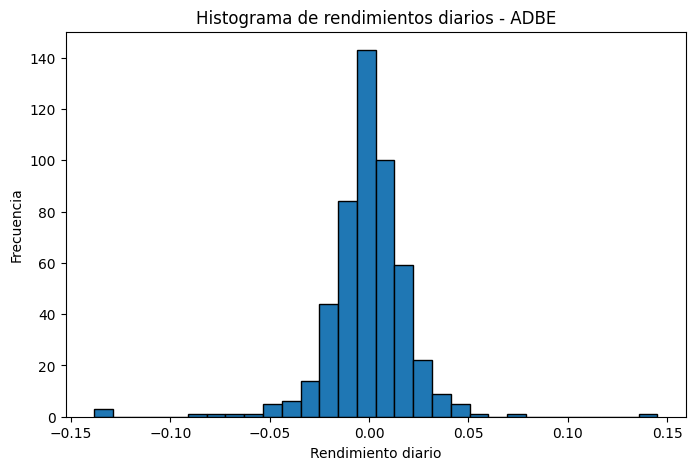

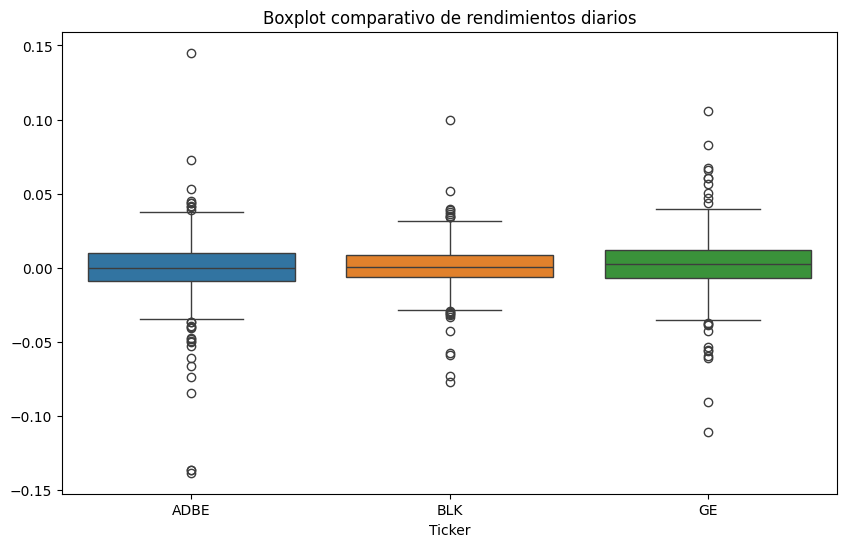

In [3]:
# 1. Calcular rendimientos
# Rendimientos diarios
rendimientos = cierres.pct_change().dropna()

# Volatilidad de cada activo
volatilidades = rendimientos.std()

print("Volatilidades:")
print(volatilidades)

# Activo más volátil
activo_volatil = volatilidades.idxmax()

print(f"Activo más volátil: {activo_volatil}")

# 2. Histograma con el activo más volátil
plt.figure(figsize=(8,5))

plt.hist(
    rendimientos[activo_volatil],
    bins=30,
    edgecolor="black"
)

plt.title(f"Histograma de rendimientos diarios - {activo_volatil}")
plt.xlabel("Rendimiento diario")
plt.ylabel("Frecuencia")
plt.show()

# 3. Boxplot comparativo de rendimientos
plt.figure(figsize=(10,6))

sns.boxplot(data=rendimientos)

plt.title("Boxplot comparativo de rendimientos diarios")
plt.show()

## 📊 Paso 4: Asociación y Correlación

1. Calcula la matriz de correlación de Pearson para los rendimientos de tus 3 activos.
2. Grafica un **mapa de calor (Heatmap)**.

### 💬 Pregunta de interpretación #3:
- ¿Existe alguna correlación fuerte (cercana a 1 o -1) entre alguno de tus activos?
- Si tuvieras que armar un portafolio de inversión buscando la **diversificación** (minimizar el riesgo conjunto), ¿qué par de activos elegirías de acuerdo a tus resultados y por qué?

"RESPUESTA ISABEL BELTRAN"
¿Existe alguna correlación fuerte?
Una correlación cercana a 1 indica que los activos suelen moverse en la misma dirección. Si alguna pareja presenta valores superiores a 0.70, puede considerarse una correlación fuerte. Una correlación cercana a cero indica una relación mas baja entre los movimientos de activos.

¿Qué activos elegiría para diversificar?

Para construir un portafolio diversificado elegiría el par de activos que presente la correlación más baja dentro del ejercicio realizado. Una correlación menor implica que los activos no reaccionan de la misma manera ante los movimientos del mercado, lo que ayuda a reducir el riesgo total del portafolio y mejora los beneficios de la diversificación.

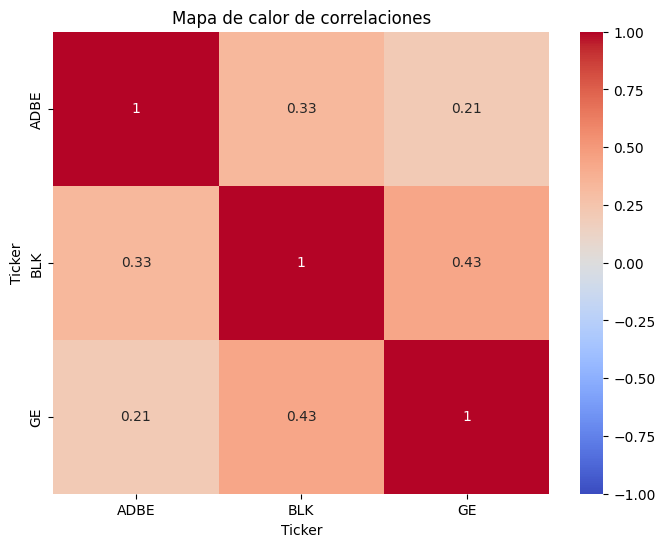

In [4]:
# 1. Calcular matriz de correlación
# Matriz de correlación
correlacion = rendimientos.corr()

correlacion

# 2. Dibujar el Heatmap utilizando Seaborn
plt.figure(figsize=(8,6))

sns.heatmap(
    correlacion,
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Mapa de calor de correlaciones")
plt.show()

## 🧮 Paso 5: Estadísticas Descriptivas y Conclusión

1. Genera un DataFrame de resumen estadístico que incluya para cada activo: Media, Mediana, Desviación Estándar, Mínimo y Máximo de los rendimientos diarios.
2. Escribe una breve conclusión final dirigida a un inversionista ficticio, interpretando los estadísticos clave obtenidos.

"RESPUESTA ISABEL BELTRAN"
Después de analizar los activos BLK, GE y ADBE durante el período entre enero de 2024 y enero de 2026, se observan diferencias importantes en términos de rendimiento y riesgo. Los rendimientos diarios muestran que algunos activos presentan una mayor estabilidad, mientras que otros experimentan variaciones más significativas. La volatilidad permite identificar el nivel de riesgo asociado a cada inversión, siendo más atractivos para perfiles conservadores aquellos activos con fluctuaciones más moderadas. Por otra parte, el análisis de correlación evidencia qué tan relacionados están los movimientos de las acciones y facilita la construcción de un portafolio más diversificado. En general, la mejor estrategia para un inversionista sería combinar aquellos activos que mantengan un buen equilibrio entre rentabilidad esperada, volatilidad y baja correlación, con el objetivo de maximizar el rendimiento y reducir el riesgo total de la cartera.

In [5]:
# Generar resumen de estadísticas descriptivas (Media, Mediana, Desviación estándar, Mínimo y Máximo)
resumen = pd.DataFrame({
    "Media": rendimientos.mean(),
    "Mediana": rendimientos.median(),
    "Desviación Estándar": rendimientos.std(),
    "Mínimo": rendimientos.min(),
    "Máximo": rendimientos.max()
})

resumen

,Media,Mediana,Desviación Estándar,Mínimo,Máximo
Ticker,,,,,
ADBE,-0.000778,-0.000325,0.021241,-0.138532,0.145115
BLK,0.000775,0.000493,0.014659,-0.077133,0.099740
GE,0.002446,0.002718,0.019161,-0.110963,0.105686
